---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 7. The ringdown of GW150914

This page was generated from [`notebooks/gw/07_gw150914_ringdown.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/07_gw150914_ringdown.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/07_gw150914_ringdown.py`.

This notebook fits the ringdown of GW150914, the first binary black hole merger observed,
in the public data of the two LIGO detectors. It follows ringdown's GW150914 example: the
same data, conditioning, start time, sky position, modes and priors. It also runs ringdown's
own fit on the same conditioned data, so the two implementations can be compared on one
analysis.

The model is that of notebooks 5 and 6, a Kerr black hole ringing in its fundamental mode
(2, 2, 0) and first overtone (2, 2, 1), with two changes that make it the same model as
ringdown's. The Kerr spectrum comes from ringdown's fits to the `qnm` package instead of the
fits of Berti, Cardoso and Will, and the polarizations carry ringdown's angular factors, so
the amplitudes are defined as in ringdown.

This notebook needs gwpy and ringdown, which are in the `ringdown` dependency group:

```bash
uv run --group ringdown marimo edit notebooks/gw/07_gw150914_ringdown.py
```

The first run downloads one 4096 s file of 16 kHz data per detector from GWOSC, about 10
minutes in all; gwpy caches them for later runs.

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

from dataclasses import dataclass

import astroinfer as ai
import gwpy.timeseries  # noqa: F401  (ringdown fetches open data through gwpy)
import jax.numpy as jnp
import marimo as mo
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import pandas as pd
import ringdown as rd
import scipy.stats
from astroinfer import MeasurementProcess, batched_method, parameter, parameter_dataclass
from astroinfer.display import html_value
from jax.scipy.linalg import solve_triangular
from numpyro.distributions import constraints
from ringdown.model import chi_factors
from ringdown.utils.swsh import calc_YpYc, construct_sYlm

# Importing gwpy changes matplotlib's defaults and replaces its default Axes class; restore
# both, so that the plots look like those of the other notebooks.
mpl.rcdefaults()
mpl.projections.register_projection(mpl.axes.Axes)

# The colors of tutorials/_style.py, and one per detector.
POSTERIOR, PRIOR, DATA, TRUTH, EXTRA = "#418FC5", "#eb6834", "#1baf7a", "#17243D", "#6250d6"
IFO_COLORS = {"H1": "#e34948", "L1": "#418FC5"}

STRAIN_UNIT = 1e-21  # strain is measured in units of 1e-21 throughout
# (p, s, l, m, n) of the modes, in ringdown's notation: the fundamental and first overtone.
RD_MODES = [(1, -2, 2, 2, 0), (1, -2, 2, 2, 1)]
MODES = ("220", "221")

# The settings of ringdown's GW150914 example.
IFOS = ["H1", "L1"]
T0 = 1126259462.4083147  # start of the analysis at geocenter, GPS
SKY = dict(ra=1.95, dec=-1.27, psi=0.82)

# ringdown's fits of the Kerr spectrum to the qnm package: the coefficients of the series in
# chi of the frequency and of the damping rate of each mode, shapes (mode, 11).
KERR_F = jnp.array([rd.qnms.KerrMode(m).coefficients[0] for m in RD_MODES])
KERR_G = jnp.array([rd.qnms.KerrMode(m).coefficients[1] for m in RD_MODES])

## Fetching and conditioning the data

The preprocessing is that of notebook 6 with the settings of ringdown's example: 32 s of
16 kHz strain around the event, high-passed above 20 Hz and downsampled by 8 to 2048 Hz, which
leaves 16 s after the edges are trimmed. The analysis starts at GPS 1126259462.4083 at
geocenter, with the sky position and polarization angle $\alpha = 1.95$, $\delta = -1.27$,
$\psi = 0.82$, and lasts 0.2 s. The PSD is estimated from the 16 s of conditioned data, which
include the signal itself; it lasts well under a second, so it changes the estimate little.

In [3]:
fit = rd.Fit(modes=RD_MODES)
fit.load_data(ifos=IFOS, channel="GWOSC", start=1126259447, end=1126259479,
              sample_rate=16384, cache=True)
fit.set_target(T0, duration=0.2, **SKY)
fit.condition_data(ds=8, f_min=20)
fit.compute_acfs(f_min=20)
{ifo: {"delay [ms]": round(1e3 * (float(fit.start_times[ifo]) - T0), 2),
       "F+": round(fit.antenna_patterns[ifo][0], 3),
       "Fx": round(fit.antenna_patterns[ifo][1], 3)}
 for ifo in fit.ifos}

{'H1': {'delay [ms]': 14.69, 'F+': 0.579, 'Fx': -0.451},
 'L1': {'delay [ms]': 7.7, 'F+': -0.527, 'Fx': 0.205}}

The signal reaches Livingston 7 ms before Hanford, and the antenna patterns of the two
detectors have opposite signs. The estimated noise of the two detectors:

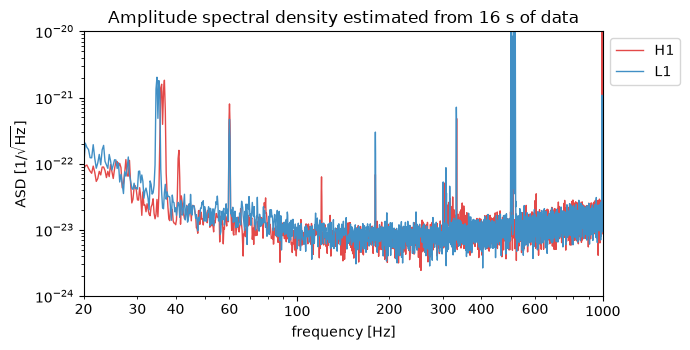

In [4]:
_fig, _ax = plt.subplots(figsize=(7.0, 3.6))
for _ifo, _psd in fit.psds.items():
    _f = np.asarray(_psd.index)
    _keep = (_f >= 20) & (_f <= 1000)
    _ax.loglog(_f[_keep], np.sqrt(np.asarray(_psd)[_keep]), color=IFO_COLORS[_ifo],
               linewidth=1, label=_ifo)
_ax.set(xlim=(20, 1000), ylim=(1e-24, 1e-20), xlabel="frequency [Hz]",
        ylabel=r"ASD [1/$\sqrt{\mathrm{Hz}}$]",
        title="Amplitude spectral density estimated from 16 s of data")
_ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

The whitened-noise check of notebook 6 cuts the 16 s of each detector into 0.2 s segments and
compares $\chi^2/n$ of each whitened segment with the $\chi^2_n/n$ distribution expected of
Gaussian noise. The segment that holds the signal is left out:

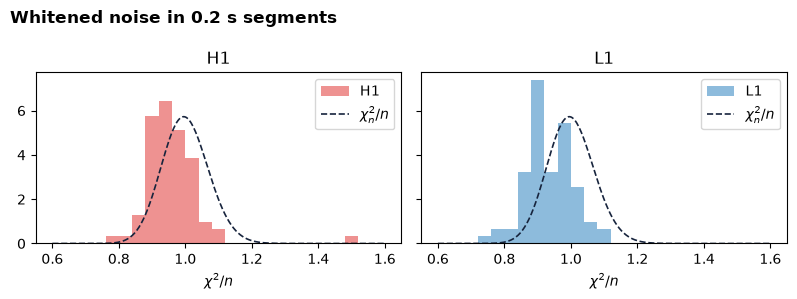

In [5]:
def whitened_chi2(ifo):
    """chi^2 / n of the analysis-length segments of one detector, without the signal's."""
    x, n = np.asarray(fit.data[ifo]), fit.n_analyze
    start = fit.start_indices[ifo]
    offsets = [j for j in range(start % n, len(x) - n, n) if abs(j - start) >= n]
    segments = np.stack([x[j:j + n] for j in offsets])
    w = np.linalg.solve(fit.cholesky_factors[ifo], segments.T)
    return np.mean(w**2, axis=0)

chi2 = {ifo: whitened_chi2(ifo) for ifo in fit.ifos}

_n = fit.n_analyze
_grid = np.linspace(0.6, 1.6, 300)
_fig, _axes = plt.subplots(1, 2, figsize=(8.0, 3.0), sharey=True)
for _ax, (_ifo, _c) in zip(_axes, chi2.items()):
    _ax.hist(_c, bins=np.linspace(0.6, 1.6, 26), density=True, color=IFO_COLORS[_ifo],
             alpha=0.6, label=_ifo)
    _ax.plot(_grid, _n * scipy.stats.chi2(_n).pdf(_n * _grid), color=TRUTH, linestyle="--",
             linewidth=1.2, label=r"$\chi^2_n/n$")
    _ax.set(xlabel=r"$\chi^2/n$", title=_ifo)
    _ax.legend(loc="upper right")
_fig.suptitle("Whitened noise in 0.2 s segments", x=0.01, ha="left", fontweight="bold")
_fig.tight_layout()
_fig

In [6]:
{ifo: {"segments": len(c), "mean": round(float(np.mean(c)), 3),
       "5%": round(float(np.percentile(c, 5)), 3),
       "95%": round(float(np.percentile(c, 95)), 3)}
 for ifo, c in chi2.items()}

{'H1': {'segments': 78, 'mean': 0.96, '5%': 0.859, '95%': 1.055},
 'L1': {'segments': 78, 'mean': 0.933, '5%': 0.827, '95%': 1.056}}

Each detector has 78 segments. Their 5% and 95% points are 0.86 and 1.06 for Hanford and
0.83 and 1.06 for Livingston, against 0.89 and 1.12 for Gaussian noise, and their means are
0.96 and 0.93. As in notebook 6, the estimated covariance is on average a few percent too
large, so the likelihood is a little broader than the noise warrants. One Hanford segment
has $\chi^2/n = 1.5$; otherwise neither detector has the long upper tail of Virgo in
notebook 6.

## The model

ringdown writes the frequency and damping rate of each mode as $f = f_0\,c_f(\chi)/M$ and
$\gamma = c_\gamma(\chi)/M$, with $c_f$ and $c_\gamma$ linear combinations of powers of
$\log(1-\chi)$ and $\log\sqrt{1-\chi^2}$ fitted to the `qnm` package. `KerrMode.coefficients`
holds the fitted coefficients, which the setup cell reads into `KERR_F` and `KERR_G`, and
`chi_factors` evaluates the series. Both are JAX functions, so we use them as they are:

In [7]:
def kerr_qnms(M, chi):
    """Frequencies [Hz] and damping rates [1/s] of the modes, from ringdown's Kerr fits."""
    f0 = 1.0 / (M * rd.qnms.T_MSUN)
    return f0 * chi_factors(chi, KERR_F), f0 * chi_factors(chi, KERR_G)

For a remnant of $70\,M_\odot$ with spin 0.7, the frequency and damping time of each mode:

In [8]:
_f, _gamma = kerr_qnms(70.0, 0.7)
{mode: f"f = {float(fi):.1f} Hz, tau = {1e3 / float(gi):.2f} ms"
 for mode, fi, gi in zip(MODES, _f, _gamma)}

{'220': 'f = 245.9 Hz, tau = 4.27 ms', '221': 'f = 240.6 Hz, tau = 1.41 ms'}

The polarizations of a mode $(\ell, m)$ seen at inclination $\iota$ carry the angular factors
$Y_+ = Y(\cos\iota) + Y(-\cos\iota)$ and $Y_\times = Y(\cos\iota) - Y(-\cos\iota)$, where
$Y = {}_{-2}Y_{\ell m}$ is the spin-weighted spherical harmonic:

$$
h_+ = \sum_n Y_{+,n}\,e^{-\gamma_n t}\left[a_{x,n}\cos 2\pi f_n t + a_{y,n}\sin 2\pi f_n t\right],\qquad
h_\times = \sum_n Y_{\times,n}\,e^{-\gamma_n t}\left[a_{x,n}\sin 2\pi f_n t - a_{y,n}\cos 2\pi f_n t\right].
$$

For the (2, 2) modes $Y \propto (1+\cos\iota)^2$, so
$Y_\times/Y_+ = 2\cos\iota/(1+\cos^2\iota)$, the ratio that notebooks 5 and 6 used; here the
factors also carry the normalization of the harmonic, as in ringdown. ringdown's example fixes
$\cos\iota = -1$, a source seen face off, for which $Y_\times = -Y_+$.

In [9]:
_swsh = construct_sYlm(-2, np.array([m[2] for m in RD_MODES]), np.array([m[3] for m in RD_MODES]))
Y_PLUS, Y_CROSS, _ = calc_YpYc(-1.0, _swsh)
Y_PLUS, Y_CROSS

(Array([1.99566312, 1.99566312], dtype=float64),
 Array([-1.99566312, -1.99566312], dtype=float64))

The types are those of notebook 6. `Remnant.qnms` now evaluates ringdown's spectrum, and
`Network` takes the angular factors as fields.

In [10]:
@parameter_dataclass(name="Remnant", latex=r"\theta_f")
class Remnant:
    M: float = parameter(name="Detector-frame mass [M_sun]", latex="M",
                         support=constraints.positive)
    chi: float = parameter(name="Dimensionless spin", latex=r"\chi",
                           support=constraints.interval(0.0, 0.99))

    @batched_method
    def qnms(self):
        """``(f, gamma)``, each with one entry per mode."""
        return kerr_qnms(self.M, self.chi)

In [11]:
@parameter_dataclass(name="Quadratures", latex="a")
class Quadratures:
    ax: float = parameter(name="Cosine quadrature [1e-21]", latex="a_x", index=("mode",),
                          index_latex=("n",))
    ay: float = parameter(name="Sine quadrature [1e-21]", latex="a_y", index=("mode",),
                          index_latex=("n",))

    @batched_method
    def amplitude(self):
        return jnp.hypot(self.ax, self.ay)

In [12]:
@parameter_dataclass(name="Kerr ringdown", latex=r"\theta")
class KerrRingdown:
    remnant: Remnant
    modes: Quadratures

In [13]:
@parameter_dataclass(name="Network strain", latex="d")
class NetworkStrain:
    h: float = parameter(name="Strain [1e-21]", latex="d", index=("ifo", "time"),
                         index_latex=("I", "k"))

In [14]:
@parameter_dataclass(name="Detector network", latex="D")
class DetectorConfig:
    t: float = parameter(name="Time since the start of the segment [s]", latex="t",
                         index=("ifo", "time"), index_latex=("I", "k"))
    fp: float = parameter(name="Plus antenna pattern", latex="F_+", index=("ifo",),
                          index_latex=("I",))
    fc: float = parameter(name="Cross antenna pattern", latex=r"F_\times", index=("ifo",),
                          index_latex=("I",))
    cholesky: float = parameter(name="Cholesky factor of the noise covariance", latex="L",
                                index=("ifo", "time", "time"), index_latex=("I", "k", "k'"))

    @classmethod
    def from_ringdown(cls, fit, scale=STRAIN_UNIT):
        """The analysis times, antenna patterns and noise of a conditioned ringdown ``Fit``."""
        ifos = fit.ifos
        return cls(
            t=jnp.stack([fit.analysis_times[i] - float(fit.start_times[i]) for i in ifos]),
            fp=jnp.array([fit.antenna_patterns[i][0] for i in ifos]),
            fc=jnp.array([fit.antenna_patterns[i][1] for i in ifos]),
            cholesky=jnp.stack([fit.cholesky_factors[i] for i in ifos]) / scale,
        )

    @property
    def shape(self):
        """``(number of detectors, number of samples)``, the core shape of the strain."""
        return self.fp.shape[-1], self.t.shape[-1]

    def project(self, hp, hc):
        """The strain in each detector from the polarizations, each of shape ``(ifo, time)``."""
        return self.fp[:, None] * hp + self.fc[:, None] * hc

    def whiten(self, x):
        """``L^{-1} x`` in each detector, for ``x`` of shape ``(ifo, time)``."""
        return jax.vmap(lambda L, y: solve_triangular(L, y, lower=True))(self.cholesky, x)

    def color(self, z):
        """``L z`` in each detector: noise with this covariance when ``z`` is standard normal."""
        return jnp.einsum("ikl,il->ik", self.cholesky, z)

    def log_likelihood(self, residual):
        """Gaussian log density of a residual of shape ``(ifo, time)``."""
        w = self.whiten(residual)
        log_det = jnp.sum(jnp.log(jnp.diagonal(self.cholesky, axis1=-2, axis2=-1)))
        return -0.5 * jnp.sum(w**2) - log_det - 0.5 * w.size * jnp.log(2 * jnp.pi)

    def snr(self, h):
        """Optimal signal-to-noise ratio of the strain ``h`` in each detector."""
        return jnp.sqrt(jnp.sum(self.whiten(h) ** 2, axis=-1))

In [15]:
def strain_from_ringdown(fit, scale=STRAIN_UNIT):
    """The analysis segments of a conditioned ringdown ``Fit`` as a ``NetworkStrain``."""
    return NetworkStrain(h=jnp.stack([np.asarray(fit.analysis_data[i]) for i in fit.ifos]) / scale)

In [16]:
@dataclass(eq=False)
class Network(MeasurementProcess):
    detectors: DetectorConfig
    y_plus: jax.Array    # Y_+ of each mode
    y_cross: jax.Array   # Y_x of each mode
    ifos: tuple = ("H1", "L1")

    display_name = "Kerr ringdown in a detector network"
    parameter_type = KerrRingdown
    data_type = NetworkStrain

    def __post_init__(self):
        # Reading the batch shape checks that the named axes agree across fields.
        if self.detectors.batch_shape:
            raise ValueError("detectors must describe one network, without batch axes")
        if len(self.ifos) != self.detectors.shape[0]:
            raise ValueError(
                f"{len(self.ifos)} detector names for {self.detectors.shape[0]} detectors"
            )

    def polarizations(self, theta):
        """``(h_+, h_x)``, each of shape ``(ifo, time)``."""
        t = self.detectors.t
        f, gamma = kerr_qnms(theta.remnant.M, theta.remnant.chi)
        phase = 2 * jnp.pi * f[:, None, None] * t
        decay = jnp.exp(-gamma[:, None, None] * t)
        ax, ay = theta.modes.ax[:, None, None], theta.modes.ay[:, None, None]
        yp, yc = self.y_plus[:, None, None], self.y_cross[:, None, None]
        hp = jnp.sum(yp * decay * (ax * jnp.cos(phase) + ay * jnp.sin(phase)), axis=0)
        hc = jnp.sum(yc * decay * (ax * jnp.sin(phase) - ay * jnp.cos(phase)), axis=0)
        return hp, hc

    def signal(self, theta):
        return self.detectors.project(*self.polarizations(theta))

    def sample_single(self, theta, key):
        noise = self.detectors.color(jax.random.normal(key, self.detectors.shape))
        return NetworkStrain(h=self.signal(theta) + noise)

    def logpdf_single(self, d, theta):
        return self.detectors.log_likelihood(d.h - self.signal(theta))

    def derived_parameters_single(self, theta):
        return {"snr": self.detectors.snr(self.signal(theta))}

    def _display_config(self):
        return {
            "detectors": html_value(self.detectors._repr_html_()),
            "names": ", ".join(self.ifos),
            "Y+": np.round(np.asarray(self.y_plus), 3).tolist(),
            "Yx": np.round(np.asarray(self.y_cross), 3).tolist(),
        }

In [17]:
network = Network(DetectorConfig.from_ringdown(fit), y_plus=jnp.asarray(Y_PLUS),
                  y_cross=jnp.asarray(Y_CROSS), ifos=tuple(fit.ifos))
data = strain_from_ringdown(fit)
mo.hstack([network, data], justify="start", gap=2, align="start")

detectors,"Detector network:\({D}\)Time since the start of the segment [s]:\({t}_{I,k} =\)[[-2.6464e-05, 0.0005, 0.001, ...], ...]Array([[-2.64644623e-05, 4.61816788e-04, 9.50098038e-04, ..., 1.98704004e-01, 1.99192286e-01, 1.99680567e-01], [ 0.00000000e+00, 4.88281250e-04, 9.76562500e-04, ..., 1.98730469e-01, 1.99218750e-01, 1.99707031e-01]], dtype=float64)shape=(2, 410)Plus antenna pattern:\({F_+}_{I} =\)[0.5787, -0.5274]Array([ 0.57874241, -0.52743343], dtype=float64)shape=(2,)Cross antenna pattern:\({F_\times}_{I} =\)[-0.4509, 0.2052]Array([-0.45094782, 0.20520961], dtype=float64)shape=(2,)Cholesky factor of the noise covariance:\({L}_{I,k,k'} =\)[[[17.0163, 0., 0., ...], ...], ...]Array(shape=(2, 410, 410), dtype=float64)shape=(2, 410, 410)Dimensions:\((\mathrm{ifo},\mathrm{time})=(I,k)\)shape=(2, 410)"
names,"H1, L1"
Y+,"[1.996, 1.996]"
Yx,"[-1.996, -1.996]"


NetworkStrain(batch_shape=(), h=(2, 410))

## The prior

The priors are ringdown's: $M$ uniform between 40 and $140\,M_\odot$, $\chi$ uniform between
0 and 0.99, and quadratures normal with an amplitude scale per mode as standard deviation,
uniform up to `a_scale_max` $= 5\times10^{-20}$, which is 50 in our units. The amplitudes
are defined as in ringdown, so the bound means the same in both.

In [18]:
def per_mode(distribution):
    """Independent copies of a scalar distribution, one per mode."""
    return distribution.expand([len(MODES)]).to_event(1)

prior = KerrRingdown.distribution(
    remnant=Remnant.distribution(M=dist.Uniform(40.0, 140.0), chi=dist.Uniform(0.0, 0.99)),
    modes=Quadratures.distribution(
        ax=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
        ay=lambda a_scale: dist.Normal(0.0, a_scale).to_event(1),
    ),
).given({"a_scale": float})

def model(data):
    a_scale = ai.sample("a_scale", per_mode(dist.Uniform(0.0, 50.0)))
    theta = ai.sample("theta", prior, a_scale=a_scale)
    ai.sample("d", network, theta, obs=data)
    f, gamma = theta.remnant.qnms()
    numpyro.deterministic("f", f)
    numpyro.deterministic("gamma", gamma)
    numpyro.deterministic("A", theta.modes.amplitude())

ai.model_graph(model, data)

Graph('Graph of model', nodes=['root:a_scale', 'root:theta', 'root:d', 'f', 'gamma', 'A'], edges=[('root:a_scale', 'root:theta'), ('root:theta', 'root:d'), ('root:theta', 'f'), ('root:theta', 'gamma'), ('root:theta', 'A')])

In [19]:
posterior = ai.infer(model, data, seed=0, num_warmup=1000, num_samples=4000, summary=False)
posterior.summary(["theta.remnant.M", "theta.remnant.chi", "f", "gamma", "A"], expand=True)

,mean,sd,5.0%,95.0%,ess,r_hat
theta.remnant.M,71.946436,8.047713,58.774498,85.085749,1064.727840,1.001073
theta.remnant.chi,0.674794,0.165609,0.428245,0.908798,926.948131,1.001625
f[0],241.185573,8.538947,227.333458,254.783116,1376.146181,1.000978
f[1],235.662693,9.990801,218.904260,251.394964,1187.661248,1.001525
gamma[0],228.862872,41.438239,162.380563,297.247383,1026.088205,1.001458
gamma[1],692.960054,128.361824,491.135553,908.618331,1020.385217,1.001467
A[0],1.790673,0.428618,1.096516,2.503014,1014.719133,1.000978
A[1],2.030862,0.828384,0.601306,3.364232,1054.305058,1.000026


The posterior mean of the mass is $71.9\,M_\odot$ with a standard deviation of 8.0, and that
of the spin is 0.67 with a standard deviation of 0.17. The fundamental mode rings at
$241.2\pm8.5$ Hz with a damping rate of $229\pm41\ \mathrm{s}^{-1}$, and the overtone at
$235.7\pm10.0$ Hz with a damping rate of $693\pm128\ \mathrm{s}^{-1}$. The amplitudes of
the two modes are $1.79\pm0.43$ and $2.03\pm0.83$ in units of $10^{-21}$. The run has no
divergent transitions.

## Comparison with ringdown

ringdown's own fit of the same conditioned data, with the settings of its example. ringdown
integrates the quadratures out of the likelihood analytically and samples only $M$, $\chi$
and the amplitude scales, while our model samples the quadratures with NUTS. The two
posteriors of $M$ and $\chi$ should agree to within sampling noise.

In [20]:
fit.update_model(a_scale_max=5e-20, m_min=40.0, m_max=140.0, cosi=-1)
fit.run(prng=0)
# Draws of every chain, flattened; the amplitudes in our units.
ringdown_posterior = {
    name: np.asarray(fit.result.posterior[name]).reshape(
        -1, *np.shape(fit.result.posterior[name])[2:])
    for name in ["m", "chi", "f", "g", "a"]
}
ringdown_posterior["a"] = ringdown_posterior["a"] / STRAIN_UNIT

The table gives the mean, the standard deviation and the equal-tailed 90% interval of each
quantity in the two posteriors. (`PosteriorData.summary` reports NumPyro's highest-density
intervals instead, which differ from these for a skewed posterior such as that of $\chi$.)

In [21]:
def describe(x):
    x = np.asarray(x).ravel()
    return {"mean": x.mean(), "sd": x.std(), "5%": np.percentile(x, 5),
            "95%": np.percentile(x, 95)}

_theta, _extras, _r = posterior.theta.theta, posterior.extras, ringdown_posterior
_pairs = {"M": (_theta.remnant.M, _r["m"]), "chi": (_theta.remnant.chi, _r["chi"])}
for _i, _mode in enumerate(MODES):
    _pairs[f"f_{_mode} [Hz]"] = (_extras["f"][..., _i], _r["f"][:, _i])
    _pairs[f"gamma_{_mode} [1/s]"] = (_extras["gamma"][..., _i], _r["g"][:, _i])
    _pairs[f"A_{_mode} [1e-21]"] = (_extras["A"][..., _i], _r["a"][:, _i])
pd.DataFrame(
    {(_name, _code): describe(_x)
     for _name, (_ours, _theirs) in _pairs.items()
     for _code, _x in [("astroinfer", _ours), ("ringdown", _theirs)]}
).T.round(3)

mean       sd       5%      95%
M               astroinfer   71.946    8.047   58.775   85.087
                ringdown     72.469    8.947   58.562   85.781
chi             astroinfer    0.675    0.166    0.339    0.870
                ringdown      0.678    0.173    0.316    0.882
f_220 [Hz]      astroinfer  241.186    8.538  226.682  254.427
                ringdown    240.943    8.812  225.456  254.169
gamma_220 [1/s] astroinfer  228.863   41.433  165.118  301.144
                ringdown    226.807   43.899  160.705  302.765
A_220 [1e-21]   astroinfer    1.791    0.429    1.123    2.534
                ringdown      1.769    0.449    1.098    2.528
f_221 [Hz]      astroinfer  235.663    9.990  218.290  250.845
                ringdown    235.490   10.295  217.235  250.668
gamma_221 [1/s] astroinfer  692.960  128.346  497.330  918.504
                ringdown    686.731  135.874  484.007  924.851
A_221 [1e-21]   astroinfer    2.031    0.828    0.661    3.440
                ringdown      2.010    0.841    0.698    3.430

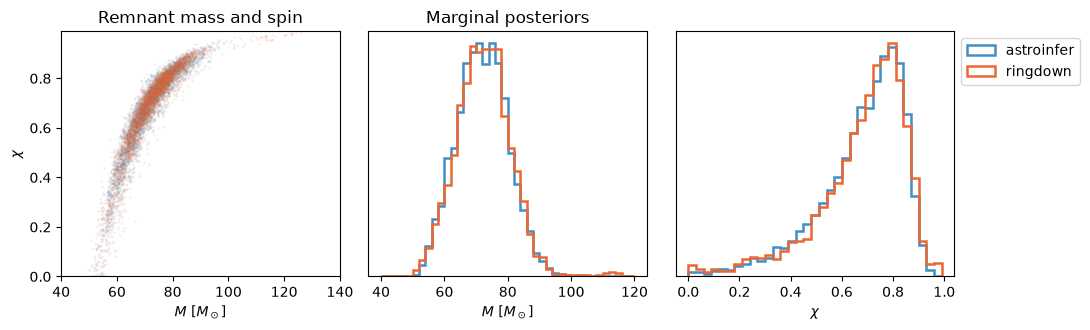

In [22]:
_theta = posterior.theta.theta
_ours = {"M": np.asarray(_theta.remnant.M).ravel(), "chi": np.asarray(_theta.remnant.chi).ravel()}
_theirs = {"M": ringdown_posterior["m"], "chi": ringdown_posterior["chi"]}

_fig, _axes = plt.subplots(1, 3, figsize=(11.0, 3.4))
_axes[0].plot(_ours["M"], _ours["chi"], ".", color=POSTERIOR, alpha=0.08, markersize=2)
_axes[0].plot(_theirs["M"], _theirs["chi"], ".", color=PRIOR, alpha=0.08, markersize=2)
_axes[0].set(xlim=(40, 140), ylim=(0, 0.99), xlabel=r"$M\ [M_\odot]$", ylabel=r"$\chi$",
             title="Remnant mass and spin")
for _ax, _name, _bins, _label in [(_axes[1], "M", np.linspace(40, 120, 41), r"$M\ [M_\odot]$"),
                                  (_axes[2], "chi", np.linspace(0, 0.99, 34), r"$\chi$")]:
    _ax.hist(_ours[_name], bins=_bins, density=True, histtype="step", color=POSTERIOR,
             linewidth=1.8, label="astroinfer")
    _ax.hist(_theirs[_name], bins=_bins, density=True, histtype="step", color=PRIOR,
             linewidth=1.8, label="ringdown")
    _ax.set(xlabel=_label, yticks=[])
_axes[1].set_title("Marginal posteriors")
_axes[2].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

The two posteriors agree. The means of $M$ are 71.9 and $72.5\,M_\odot$, with standard
deviations of 8.0 and 8.9, and the means of $\chi$ are 0.675 and 0.678, with standard
deviations of 0.166 and 0.173. The differences are the size of ringdown's own scatter
between seeds: without `prng=0`, a run of ringdown gave $M = 72.6\pm8.4\,M_\odot$. The
frequencies, damping rates and amplitudes agree as closely; the amplitudes can be compared
directly because both models use the same angular factors. ringdown's documentation reports
$M = 72.1\pm8.2\,M_\odot$ and $\chi = 0.68\pm0.17$ for this example.

## The reconstructed signal

The whitened data of each detector, with the 90% band of the whitened signal over 1000
posterior draws:

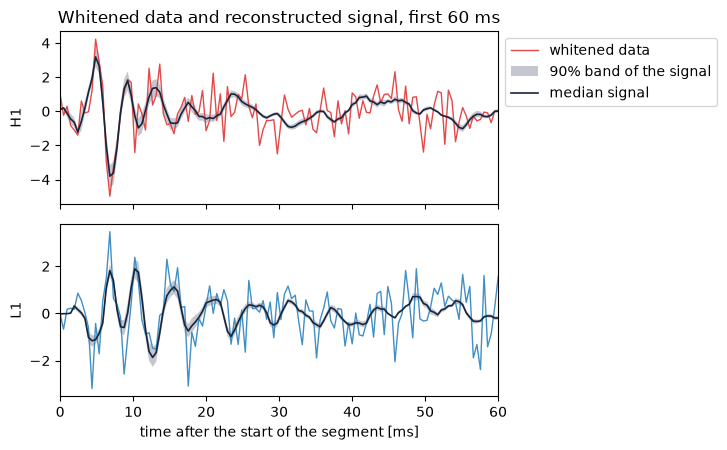

In [23]:
_theta = posterior.theta.theta
_draws = _theta.reshape_batch((int(np.prod(_theta.batch_shape)),))[:1000]
_wh = np.asarray(jax.vmap(lambda th: network.detectors.whiten(network.signal(th)))(_draws))
_lo, _mid, _hi = np.percentile(_wh, [5, 50, 95], axis=0)
_wd = np.asarray(network.detectors.whiten(data.h))
_t = 1e3 * np.asarray(network.detectors.t[0])

_fig, _axes = plt.subplots(len(network.ifos), 1, figsize=(7.5, 4.6), sharex=True)
for _i, (_ax, _ifo) in enumerate(zip(_axes, network.ifos)):
    _ax.plot(_t, _wd[_i], color=IFO_COLORS[_ifo], linewidth=1, label="whitened data")
    _ax.fill_between(_t, _lo[_i], _hi[_i], color=TRUTH, alpha=0.25, linewidth=0,
                     label="90% band of the signal")
    _ax.plot(_t, _mid[_i], color=TRUTH, linewidth=1.2, label="median signal")
    _ax.set(ylabel=_ifo, xlim=(0, 60))
_axes[0].set_title("Whitened data and reconstructed signal, first 60 ms")
_axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_axes[-1].set(xlabel="time after the start of the segment [ms]")
_fig.tight_layout()
_fig

The whitened signal keeps oscillating after 30 ms, although the signal itself has decayed by
then to about $10^{-3}$ of its peak strain. The oscillation comes from the whitening. $L^{-1}$
is a causal filter, and for a PSD estimated from 16 s of data its response to a pulse in the
first 10 ms still has about half of its peak amplitude 30 to 60 ms later.